In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [2]:
# Add the path to sys.path
sys.path.append(os.path.abspath("../../Ants_move/main_analysis/"))

# Import from the script file name
from plot_utils_and_functions import *

In [3]:
np.random.seed(0)
torch.manual_seed(0)
random.seed(0)

In [4]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [5]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/phd/pytorch_DGN/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [6]:
work_folder = 'edge_spen'
saving_folder = 'l0'
os.chdir(work_folder)

In [7]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [8]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)
print(s0)

2.1484375


In [9]:
vision=state_dim[-1]
from ppo_ants import *

In [10]:
def setup_environment(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        tmax, n_special, t_transient, vision,
                        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
                        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                        state_dim, action_dim, clip_grad):
    
    env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])
    
    sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

    config_net_file = f"{saving_folder}/networks.yaml"
    ppo_ants = PPO_ants( env,
                    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                    state_dim, action_dim, clip_grad)

    return env, ppo_ants

In [11]:
env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad
)

In [12]:
critic_test = 'weights/critic.pth'
actor_test = 'weights/actor.pth'

In [13]:
def load_policy_weights(ppo_ants, actor_test, critic_test, saving_folder):
    if not os.path.exists(f"{saving_folder}/{critic_test}"):
        print(f"Warning: {critic_test} or {actor_test} not found in {saving_folder}. Using default weights.")
    else:
        ppo_ants.critic.load_state_dict(torch.load(f"{saving_folder}/{critic_test}", weights_only=True))
        ppo_ants.actor.load_state_dict(torch.load(f"{saving_folder}/{actor_test}", weights_only=True))

In [14]:
import torch.distributions as distributions
def test_forward_pass(self, max_prob=False, save_pos = False, reset=True):

    states, actions, rewards, done, episode_reward = [], [], [], False, 0.0
    if reset:
        self.env.reset_objects()
    self.env.transient()
    self.actor.eval()
    self.critic.eval()
    
    state = self.get_state().copy()
    state_tensor = torch.FloatTensor(state)

    if save_pos:
        pos = []
        pher = []

    while not done:

               
        # Get action probabilities and value prediction from the agent.
        action_pred = self.actor(state_tensor)
        action_prob = F.softmax(action_pred, dim=-1)
        dist = distributions.Categorical(action_prob)
        action = dist.sample()
        
        if max_prob:
            action = np.argmax(action_prob.detach(), axis=1)

        # Store log probability of the selected action.
        new_state, reward, done = self.execute_action(action.detach().numpy())
        
        rewards.append(reward)
        episode_reward += np.mean(reward)
        actions.append(action)
        if save_pos:
            pos.append(self.env.positions.copy())
            pher.append(self.env.pheromones.copy())

        state = new_state.copy() 
        state_tensor = torch.FloatTensor(state)
        states.append(state_tensor)


    # Convert to tensors and calculate advantages (returns - values).
    states = torch.cat(states)

    if save_pos: 
        return episode_reward, states, torch.cat(actions), rewards, pos, pher

    else:
        return episode_reward, states, torch.cat(actions), rewards

In [15]:
policies = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
delta_list = delta
beta_list = beta

In [16]:
'''env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad
)

ppo_ants.setup_networks()

load_policy_weights(ppo_ants, actor_test, critic_test)

b = 3.5
d = 0.4

ppo_ants.env.reset_objects()
ppo_ants.env.delta[:] = np.ones(n+n_special) * d
ppo_ants.env.beta[:] = np.ones(n+n_special) * b

episode_reward, states, actions, rewards, pos, pher = test_forward_pass(ppo_ants, max_prob=False, save_pos=True,
                                                                        reset=False)'''

'env, ppo_ants = setup_environment(\n    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,\n    tmax, n_special, t_transient, vision,\n    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,\n    clip_epsilon, entropy_coeff, policy_steps, learning_steps,\n    state_dim, action_dim, clip_grad\n)\n\nppo_ants.setup_networks()\n\nload_policy_weights(ppo_ants, actor_test, critic_test)\n\nb = 3.5\nd = 0.4\n\nppo_ants.env.reset_objects()\nppo_ants.env.delta[:] = np.ones(n+n_special) * d\nppo_ants.env.beta[:] = np.ones(n+n_special) * b\n\nepisode_reward, states, actions, rewards, pos, pher = test_forward_pass(ppo_ants, max_prob=False, save_pos=True,\n                                                                        reset=False)'

In [17]:
simulation = False
if simulation:
    for seed in policies:
            
            saving_folder = 'l' + str(seed)

            env, ppo_ants = setup_environment(
                n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                tmax, n_special, t_transient, vision,
                gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
                clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                state_dim, action_dim, clip_grad
            )

            ppo_ants.setup_networks()
            load_policy_weights(ppo_ants, actor_test, critic_test, saving_folder)
            for b in beta:
                for d in delta:


                    ppo_ants.env.reset_objects()
                    ppo_ants.env.delta[:] = np.ones(n+n_special) * d
                    ppo_ants.env.beta[:] = np.ones(n+n_special) * b

                    episode_reward, states, actions, rewards, pos, pher = test_forward_pass(ppo_ants, max_prob=False, save_pos=True,
                                                                                            reset=False)
                    pos = np.array(pos)
                    pher = np.array(pher)

                    np.savez(f"entropy/test_results_delta_{d}_beta_{b}_rand_l{seed}.npz", pos=pos, pher=pher)
                

In [18]:
L = 32  # Dimensione della griglia / box

# 1. Definisci qui la tua lista di lag desiderati
lag_list = [1, 2, 5, 10, 20, 32, 50, 60]
num_lags = len(lag_list)

# Matrici di supporto per i risultati
collective_entropy_results = np.zeros((len(policies), len(beta), len(delta)))
individual_entropy_results = np.zeros((len(policies), len(beta), len(delta)))
individual_entropy_std_results = np.zeros((len(policies), len(beta), len(delta)))
mutual_info_results = np.zeros((len(policies), len(beta), len(delta)))

# Nuove misure (allocate con la dimensione num_lags)
extent_results = np.zeros((len(policies), len(beta), len(delta)))
msd_results = np.zeros((len(policies), len(beta), len(delta), num_lags))
persistence_results = np.zeros((len(policies), len(beta), len(delta), num_lags))

tau = 100  # Ultimi 100 time step

for sim in policies:
    for b in beta:
        for d in delta:

            # 1. Carica il file .npz
            filename = f"entropy/test_results_delta_{d}_beta_{b}_rand_l{sim}.npz"
            data = np.load(filename)
            pos = data['pos']  # Shape: (1000, 330, 2)
    
            # 2. Ultimi tau time step e primi n individui
            pos_last_tau = pos[-tau:, :n]  # Shape: (tau, num_ants, 2)
            num_timesteps, num_ants, _ = pos_last_tau.shape
    
            # -------------------------------------------------------------
            # A. ENTROPIA, MUTUAL INFORMATION ED ESTENSIONE SPAZIALE (E)
            # -------------------------------------------------------------
            flat_pos = pos_last_tau.reshape(-1, 2)
            _, inverse_indices = np.unique(flat_pos, axis=0, return_inverse=True)
            cell_ids = inverse_indices.reshape(num_timesteps, num_ants)
            num_cells = np.max(cell_ids) + 1  # Numero totale di celle uniche visitate
                
            p_ik = np.zeros((num_cells, num_ants))
            for k in range(num_ants):
                p_ik[:, k] = np.bincount(cell_ids[:, k], minlength=num_cells) / num_timesteps
    
            with np.errstate(divide='ignore', invalid='ignore'):
                log2_p_ik = np.where(p_ik > 0, np.log2(p_ik), 0.0)
                individual_entropies = -np.sum(p_ik * log2_p_ik, axis=0)

            p_i = np.mean(p_ik, axis=1)
            with np.errstate(divide='ignore', invalid='ignore'):
                log2_p_i = np.where(p_i > 0, np.log2(p_i), 0.0)
                h_coll = -np.sum(p_i * log2_p_i)

            h_ind = np.mean(individual_entropies)
            mutual_info = h_coll - h_ind

            # Estensione spaziale E: celle uniche visitate da ogni formica in finestra T
            E_k = np.array([len(np.unique(pos_last_tau[:, k, :], axis=0)) for k in range(num_ants)])
            E = np.mean(E_k)

            # -------------------------------------------------------------
            # B. PBC, UNWRAPPING, MSD(l) E PERSISTENZA DIREZIONALE C(l)
            # -------------------------------------------------------------
            # 1. Spostamenti passo-passo raw
            dx = np.diff(pos_last_tau, axis=0)  # Shape: (tau-1, num_ants, 2)
            
            # 2. Correzione PBC per gli spostamenti passo-passo
            dx_pbc = dx - L * np.round(dx / L)
            
            # 3. Traiettoria srotolata (Unwrapped) per il calcolo corretto di MSD
            pos_unwrap = np.zeros_like(pos_last_tau)
            pos_unwrap[0] = pos_last_tau[0]
            pos_unwrap[1:] = pos_last_tau[0] + np.cumsum(dx_pbc, axis=0)

            # 4. Calcolo dei vettori unitari di direzione u_k(t)
            step_norms = np.linalg.norm(dx_pbc, axis=-1, keepdims=True)
            u_k = np.where(step_norms > 1e-8, dx_pbc / step_norms, 0.0)  # Shape: (tau-1, num_ants, 2)

            # 5. Calcolo di MSD(l) e C(l) iterando direttamente su lag_list
            msd_l = np.zeros(num_lags)
            c_l = np.zeros(num_lags)

            for idx, lag in enumerate(lag_list):
                # MSD: spostamento srotolato al tempo (t + lag) rispetto a t
                if lag < tau:
                    disp = pos_unwrap[lag:] - pos_unwrap[:-lag]  # (tau - lag, num_ants, 2)
                    msd_l[idx] = np.mean(np.sqrt(np.sum(disp**2, axis=-1)))
                else:
                    msd_l[idx] = np.nan

                # C(l): Prodotto scalare tra vettori direzione distanziati di 'lag'
                if lag < len(u_k):  # len(u_k) è tau - 1
                    u_t = u_k[:-lag]
                    u_t_lag = u_k[lag:]
                    dot_products = np.sum(u_t * u_t_lag, axis=-1)  # (tau - 1 - lag, num_ants)
                    c_l[idx] = np.mean(dot_products)
                else:
                    c_l[idx] = np.nan

            # -------------------------------------------------------------
            # C. SALVATAGGIO DEI RISULTATI
            # -------------------------------------------------------------
            bi, di = beta.index(b), delta.index(d)

            collective_entropy_results[sim, bi, di] = h_coll/np.log2(L**2)  # Normalizzazione
            individual_entropy_results[sim, bi, di] = h_ind
            individual_entropy_std_results[sim, bi, di] = np.std(individual_entropies)
            mutual_info_results[sim, bi, di] = mutual_info
            extent_results[sim, bi, di] = E
            msd_results[sim, bi, di, :] = msd_l
            persistence_results[sim, bi, di, :] = c_l

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244454/852511403.py:6: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

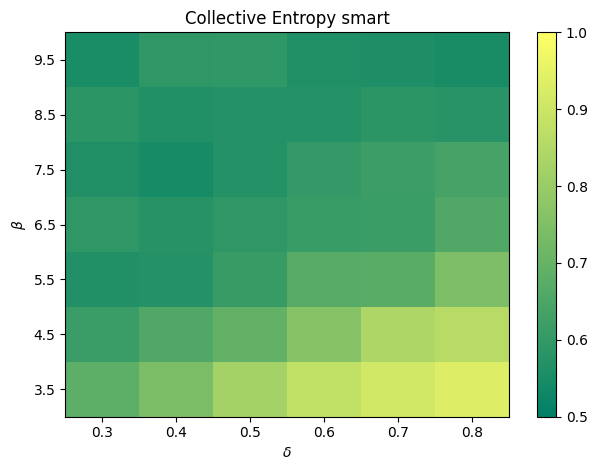

In [19]:
plt.figure(figsize=(8, 6))
entropy_results = np.mean(collective_entropy_results, axis=0)  # Media su tutte le simulazioni
'''plt.imshow(entropy_results, origin='lower', extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)],
            aspect='auto', cmap='summer', vmin=0.5, vmax=1)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')  
plt.ylabel(r'$\beta$')'''

plot_heatmap(entropy_results, delta_list, beta_list,
              title='Collective Entropy smart', cmap='summer', vmin=0.5, vmax=1)

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244454/1509078472.py:6: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

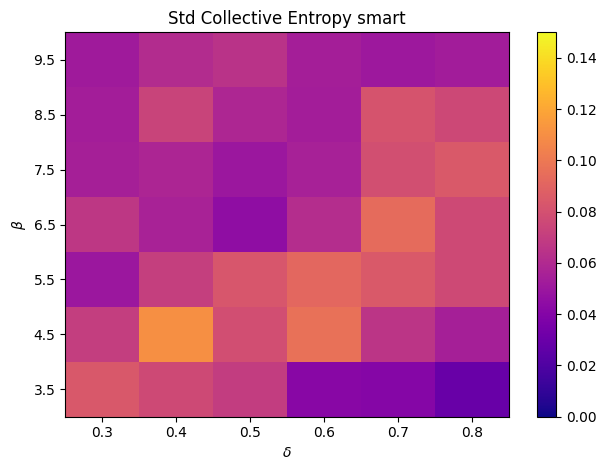

In [20]:
plt.figure(figsize=(8, 6))
std_entropy_results = np.std(collective_entropy_results, axis=0)  # Media su tutte le simulazioni
'''plt.imshow(std_entropy_results, origin='lower', extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)],
            aspect='auto', cmap='plasma')#, vmin=0.5, vmax=1)
plt.colorbar(label=r'${std(H)}$')
plt.xlabel(r'$\delta$')  
plt.ylabel(r'$\beta$')'''

plot_heatmap(std_entropy_results, delta_list, beta_list,
              title='Std Collective Entropy smart', cmap='plasma', vmin=0.0, vmax=0.15)

<>:16: SyntaxWarning: invalid escape sequence '\d'
<>:16: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244454/3956820638.py:16: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

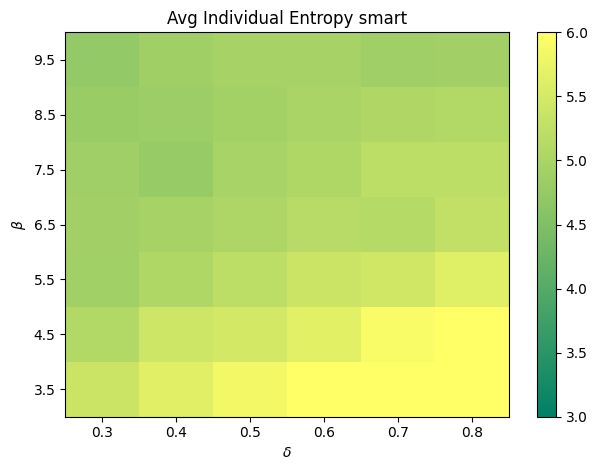

In [21]:
plt.figure(figsize=(8, 6))
avg_entropy = individual_entropy_results.mean(axis=0)  # Media su tutte le simulazioni  
'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.imshow(
    avg_entropy,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='summer',
    vmin=3,
    vmax=6
)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')'''

plot_heatmap(avg_entropy, delta_list, beta_list,
              title='Avg Individual Entropy smart', cmap='summer', vmin=3, vmax=6)

<>:14: SyntaxWarning: invalid escape sequence '\d'
<>:14: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244454/2243268216.py:14: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

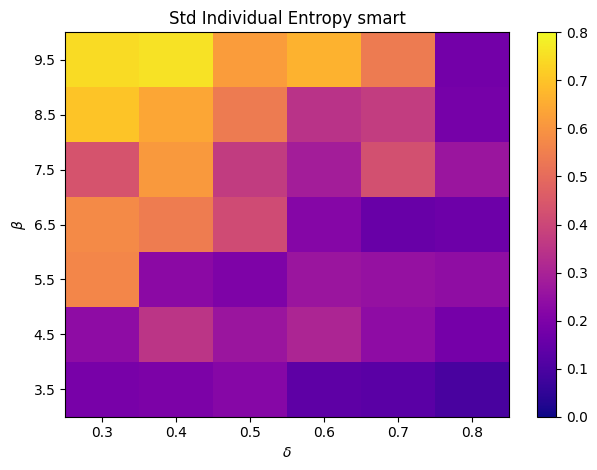

In [26]:
plt.figure(figsize=(8, 6))
std_entropy = individual_entropy_results.std(axis=0)  # Media su tutte le simulazioni  
'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.imshow(
    std_entropy,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='plasma'
)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')'''

plot_heatmap(std_entropy, delta_list, beta_list,
              title='Std Individual Entropy smart', cmap='plasma', vmin=0.0, vmax=0.8)

<>:21: SyntaxWarning: invalid escape sequence '\d'
<>:21: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244454/2911481865.py:21: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


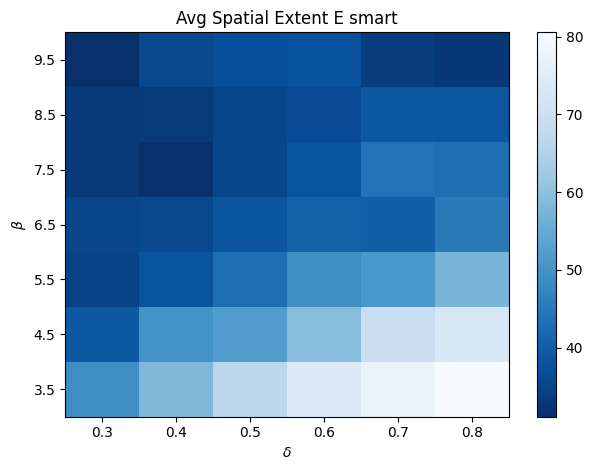

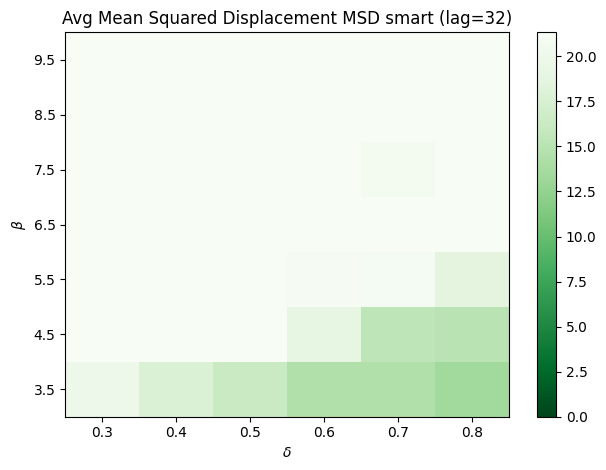

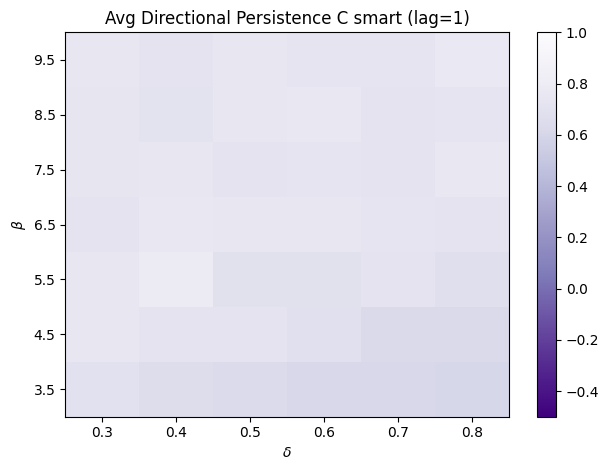

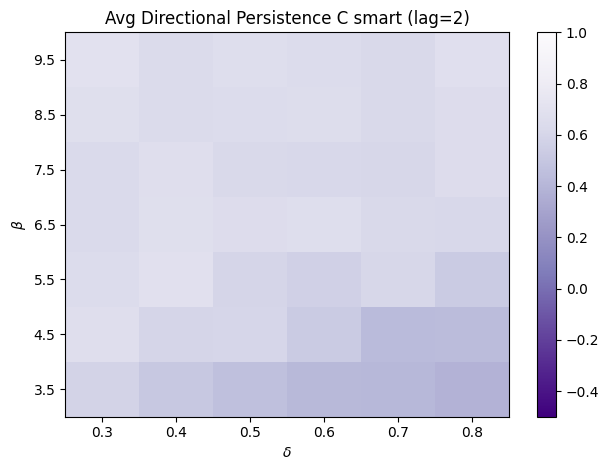

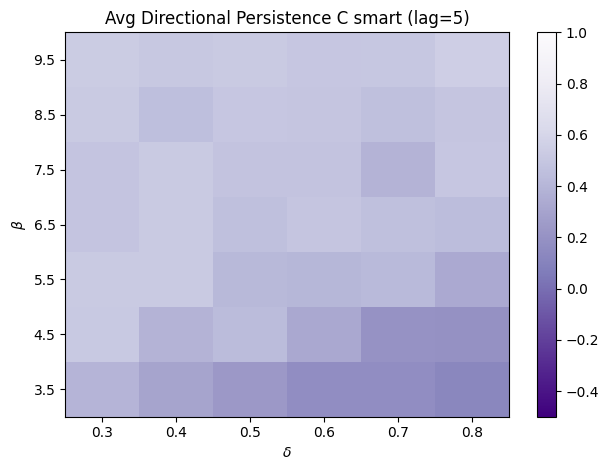

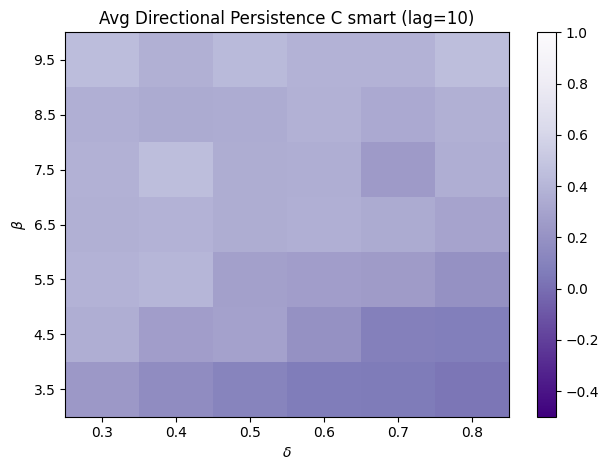

In [23]:
# 1. Media dell'Informazione Mutua lungo le simulazioni (axis=0)
avg_extent_results = np.mean(extent_results, axis=0)
avg_msd_results = np.mean(msd_results, axis=0)
avg_persistence_results = np.mean(persistence_results, axis=0)
chosen_lag = 32  # Lag scelto per visualizzare MSD(l) e C(l)
index_of_chosen_lag = lag_list.index(chosen_lag)  # Ottieni l'indice del lag scelto
lags_for_directional_persistence = [1,2,5,10]
'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.figure(figsize=(8, 6))
plt.imshow(
    avg_extent_results,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Blues_r'
)
plt.colorbar(label=r'$E$')

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Average Spatial Extent $E$ smart')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(
    avg_msd_results[:,:,index_of_chosen_lag],  # Visualizza MSD al lag scelto
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Greens_r',
    vmin=0, vmax=chosen_lag*2/3
)
plt.colorbar(label=r'$MSD(l)$')  # Aggiunta della barra del colore per MSD

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Average Mean Squared Displacement $MSD(l)$ smart')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(
    avg_persistence_results[:,:,index_of_chosen_lag],  # Visualizza C(l) al lag scelto
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Purples_r'
)
plt.colorbar(label=r'$C(l)$')  # Aggiunta della barra del colore per C(l)

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Average Directional Persistence $C(l)$ smart')
plt.tight_layout()
plt.show()'''

plot_heatmap(avg_extent_results, delta_list, beta_list,
              title='Avg Spatial Extent E smart', cmap='Blues_r')
plot_heatmap(avg_msd_results[:,:,index_of_chosen_lag], delta_list, beta_list,
              title=f'Avg Mean Squared Displacement MSD smart (lag={chosen_lag})', cmap='Greens_r', vmin=0, vmax=chosen_lag*2/3)

for lag_for_directional_persistence in lags_for_directional_persistence:
    index_of_lag_for_directional_persistence = lag_list.index(lag_for_directional_persistence)  # Ottieni l'indice del lag scelto per la persistenza direz
    plot_heatmap(avg_persistence_results[:,:,index_of_lag_for_directional_persistence], delta_list, beta_list,
              title=f'Avg Directional Persistence C smart (lag={lag_for_directional_persistence})', cmap='Purples_r',
                vmin=-0.5, vmax=1)

<>:20: SyntaxWarning: invalid escape sequence '\d'
<>:20: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244454/4134367450.py:20: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


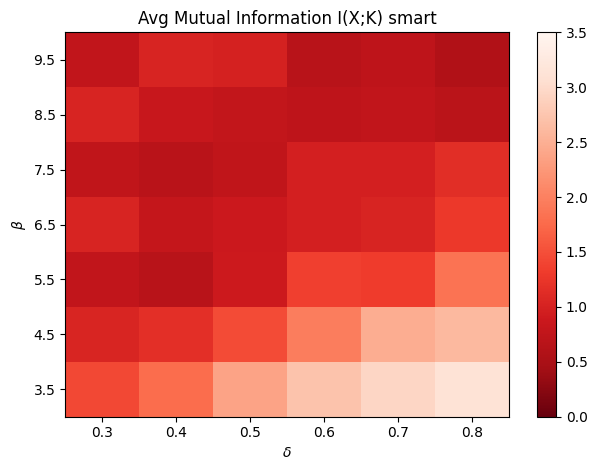

In [24]:
# 1. Media dell'Informazione Mutua lungo le simulazioni (axis=0)
avg_mutual_info = np.mean(mutual_info_results, axis=0)

'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

# 2. Creazione della figura
plt.figure(figsize=(8, 6))
plt.imshow(
    avg_mutual_info,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Reds_r',  # 'viridis' o 'plasma' mettono in risalto i valori di informazione mutua; puoi usare 'summer' se preferisci la stessa palette
    vmin=0,        # scommenta e imposta se vuoi fissare la scala minima
    vmax=3.5        # scommenta e imposta se vuoi fissare la scala massima
)

plt.colorbar(label=r'$I(X; K)$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Mutual Information $I(X; K)$ smart')
plt.tight_layout()
plt.show()'''

plot_heatmap(avg_mutual_info, delta_list, beta_list,
              title='Avg Mutual Information I(X;K) smart', cmap='Reds_r', vmin=0, vmax=3.5)

In [25]:
# Liste dei valori desiderati nelle righe e colonne della tabella
beta_target = [9.5, 8.5, 7.5, 6.5, 5.5, 4.5, 3.5]
delta_target = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

# Esempio d'uso:
print_latex_block(entropy_results, avg_entropy, beta_list, delta_list)

9.5 & 0.55 & 0.59 & 0.60 & 0.56 & 0.56 & 0.55 & 4.74 & 4.88 & 4.97 & 4.97 & 4.87 & 4.91 \\
8.5 & 0.59 & 0.57 & 0.57 & 0.57 & 0.58 & 0.58 & 4.81 & 4.83 & 4.93 & 5.00 & 5.07 & 5.10 \\
7.5 & 0.56 & 0.55 & 0.57 & 0.60 & 0.62 & 0.64 & 4.87 & 4.77 & 4.97 & 5.06 & 5.22 & 5.22 \\
6.5 & 0.59 & 0.58 & 0.59 & 0.61 & 0.62 & 0.66 & 4.91 & 4.95 & 5.04 & 5.15 & 5.13 & 5.28 \\
5.5 & 0.57 & 0.57 & 0.61 & 0.67 & 0.68 & 0.75 & 4.90 & 5.06 & 5.20 & 5.38 & 5.44 & 5.61 \\
4.5 & 0.61 & 0.66 & 0.69 & 0.76 & 0.84 & 0.86 & 5.09 & 5.42 & 5.47 & 5.65 & 5.92 & 6.00 \\
3.5 & 0.68 & 0.74 & 0.82 & 0.88 & 0.91 & 0.93 & 5.38 & 5.63 & 5.85 & 6.05 & 6.13 & 6.21 \\
